本 notebook 是 [M04.2 线性模型](../notes/02-linear-models.qmd) 的实例讲解，用可运行的代码把讲义里的几个关键结论“看出来”：

1. 最小二乘是正交投影：残差与列空间正交，投影矩阵幂等；
2. 为什么不要显式解正规方程：条件数被平方；
3. 共线性下 OLS 系数方差爆炸，而预测误差几乎不变；
4. Ridge 的收缩因子与有效自由度；
5. Lasso 把系数**精确**置零；
6. 线性可分数据上的逻辑回归：权重发散与正则化。

本章另有从零实现的练习（[exercises/](../exercises/README.md)），所以这里的模型拟合一律调用 NumPy / scikit-learn，不展示练习函数的实现。

**运行方式**：在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行。全部单元在 CPU 上约 10 秒内完成。改动代码后可用 `make nb M=04` 重新执行并保存输出。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge

from semiai.plotting import BLUE, GRAY, MUTED, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(0)
np.set_printoptions(precision=4, suppress=True)

## 1. 最小二乘是正交投影

讲义的[正规方程](../notes/02-linear-models.qmd#eq-normal)说：最优解处残差 $\mathbf{r} = \mathbf{y} - X\hat{\mathbf{w}}$ 与 $X$ 的每一列正交。下面用 `np.linalg.lstsq` 求解（它内部用 SVD），然后直接检查这几个性质。

In [2]:
n, d = 50, 3
X = rng.normal(size=(n, d))
y = X @ np.array([1.0, -2.0, 0.5]) + 0.3 * rng.normal(size=n)

w_hat, *_ = np.linalg.lstsq(X, y, rcond=None)
r = y - X @ w_hat
P = X @ np.linalg.pinv(X)  # 投影到 col(X) 的矩阵，等于 X (X^T X)^{-1} X^T

print("w_hat            =", w_hat)
print("X^T r            =", X.T @ r, " ← 残差与每一列正交，数值上 ~1e-15")
print("||P^2 - P||      =", np.linalg.norm(P @ P - P))
print("||P - P^T||      =", np.linalg.norm(P - P.T))
print("tr(P) = rank(X)  =", np.trace(P).round(6))

w_hat            = [ 1.0553 -2.0484  0.5057]
X^T r            = [-0.  0.  0.]  ← 残差与每一列正交，数值上 ~1e-15
||P^2 - P||      = 8.829880456984716e-16
||P - P^T||      = 6.138416590473428e-16
tr(P) = rank(X)  = 3.0


`tr(P)` 等于 3，也就是模型使用的参数个数。这就是 M04.1 中“自由度”的定义来源；Ridge 的有效自由度（第 4 节）是它的连续推广。

## 2. 不要显式解正规方程

$X^\top X$ 的条件数是 $X$ 的平方。构造一个奇异值从 1 衰减到 $10^{-7}$ 的设计矩阵，对比两种解法相对真实系数的误差。

In [3]:
def design_with_condition(n: int, d: int, kappa: float, rng: np.random.Generator) -> np.ndarray:
    """生成 cond(X) = kappa 的 n×d 设计矩阵：随机正交基 + 指定的奇异值。"""
    U, _ = np.linalg.qr(rng.normal(size=(n, d)))
    V, _ = np.linalg.qr(rng.normal(size=(d, d)))
    sigma = np.logspace(0, -np.log10(kappa), d)
    return U @ np.diag(sigma) @ V.T


def rel_err(w: np.ndarray, w_ref: np.ndarray) -> float:
    return float(np.linalg.norm(w - w_ref) / np.linalg.norm(w_ref))


w_true = np.ones(8)
rows = []
for kappa in (1e2, 1e4, 1e6, 1e7):
    Xc = design_with_condition(200, 8, kappa, rng)
    yc = Xc @ w_true  # 无噪声：误差全部来自浮点舍入
    w_lstsq, *_ = np.linalg.lstsq(Xc, yc, rcond=None)
    w_normal = np.linalg.solve(Xc.T @ Xc, Xc.T @ yc)
    rows.append(
        {
            "cond(X)": f"{kappa:.0e}",
            "cond(XᵀX)": f"{np.linalg.cond(Xc.T @ Xc):.1e}",
            "lstsq 相对误差": f"{rel_err(w_lstsq, w_true):.1e}",
            "正规方程相对误差": f"{rel_err(w_normal, w_true):.1e}",
        }
    )
pd.DataFrame(rows).set_index("cond(X)")

,cond(XᵀX),lstsq 相对误差,正规方程相对误差
cond(X),,,
1e+02,1.0e+04,6.5e-16,1.0e-13
1e+04,1.0e+08,3.0e-14,3.4e-09
1e+06,1.0e+12,3.2e-12,2.5e-05
1e+07,1.0e+14,2.4e-11,3.0e-03


读法：误差大致等于“条件数 × 机器精度 $\approx 2\times10^{-16}$”。`lstsq` 面对的是 $\kappa(X)$，正规方程面对的是 $\kappa(X)^2$。$\kappa(X)=10^7$ 时，后者只剩一两位有效数字。

## 3. 共线性：系数不可信，预测却不差

两个特征的相关系数 $\rho$ 从 0 增加到 0.999，真实系数固定为 $(1, 1)$。每个 $\rho$ 重复生成 300 份训练集，统计第一个系数在重复之间的标准差和测试 RMSE。这是 [examples/collinearity_demo.py](../examples/collinearity_demo.py) 的精简可视化版。

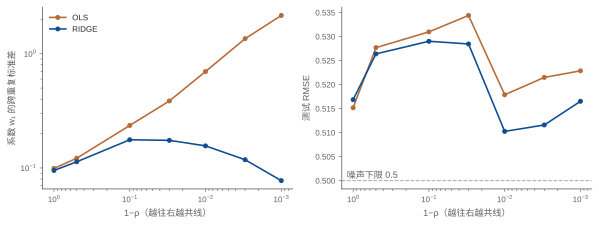

In [4]:
def sample(rho: float, n: int, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    cov = np.array([[1.0, rho], [rho, 1.0]])
    Xs = rng.multivariate_normal(np.zeros(2), cov, size=n)
    return Xs, Xs @ np.array([1.0, 1.0]) + 0.5 * rng.normal(size=n)


rhos = np.array([0.0, 0.5, 0.9, 0.97, 0.99, 0.997, 0.999])
stats = {"ols": [], "ridge": []}
for rho in rhos:
    X_test, y_test = sample(rho, 2000, rng)
    coefs = {"ols": [], "ridge": []}
    rmse = {"ols": [], "ridge": []}
    for _ in range(300):
        Xs, ys = sample(rho, 30, rng)
        for name, model in (("ols", LinearRegression()), ("ridge", Ridge(alpha=1.0))):
            model.fit(Xs, ys)
            coefs[name].append(model.coef_[0])
            rmse[name].append(np.sqrt(np.mean((model.predict(X_test) - y_test) ** 2)))
    for name in stats:
        stats[name].append((np.std(coefs[name]), np.mean(rmse[name])))
stats = {k: np.array(v) for k, v in stats.items()}

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2))
for name, color in (("ols", ORANGE), ("ridge", BLUE)):
    axes[0].plot(1 - rhos, stats[name][:, 0], "o-", color=color, label=name.upper())
    axes[1].plot(1 - rhos, stats[name][:, 1], "o-", color=color, label=name.upper())
for ax in axes:
    ax.set_xscale("log")
    ax.invert_xaxis()
    ax.set_xlabel("1−ρ（越往右越共线）")
axes[0].set_yscale("log")
axes[0].set_ylabel("系数 w₁ 的跨重复标准差")
axes[1].set_ylabel("测试 RMSE")
axes[1].axhline(0.5, color=GRAY, lw=1, ls="--")
axes[1].text(0.02, 0.06, "噪声下限 0.5", transform=axes[1].transAxes, color=MUTED, fontsize=9)
axes[0].legend()
fig.tight_layout()
plt.show()

左图：$\rho\to1$ 时 OLS 单个系数的标准差增大二十多倍，Ridge 反而略有下降。右图：两者的测试 RMSE 都贴着噪声下限。原因是预测只依赖被数据良好约束的 $w_1+w_2$，而 $w_1-w_2$ 方向几乎没有约束（[讲义 OLS 的 SVD 形式](../notes/02-linear-models.qmd#eq-ols-svd)中 $1/\sigma_i$ 很大的方向）。**预测好不等于系数可信。**

## 4. Ridge 的收缩因子与有效自由度

[讲义 Ridge 的 SVD 形式](../notes/02-linear-models.qmd#eq-ridge-svd)：Ridge 在第 $i$ 个奇异方向上乘以 $f_i = \sigma_i^2/(\sigma_i^2+\alpha)$。把它们加起来就是有效自由度 $\mathrm{df}(\alpha)=\sum_i f_i$。下面只计算这些因子，并用 scikit-learn 的 `Ridge` 验证 $\mathrm{df}$ 等于帽子矩阵的迹。

alpha = 0.01
  tr(H)，由 sklearn Ridge 得到 = 8.60769036
  sum f_i，由奇异值计算      = 8.60769036


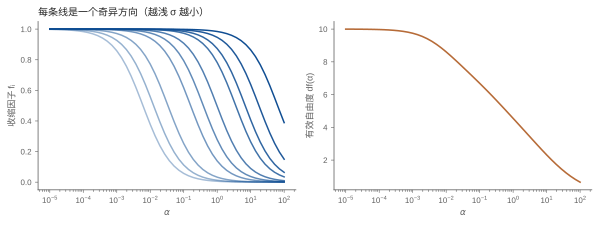

In [5]:
Xr = rng.normal(size=(60, 10)) @ np.diag(np.logspace(0, -2, 10))  # 奇异值跨两个数量级
Xr -= Xr.mean(0)
sigma = np.linalg.svd(Xr, compute_uv=False)
alphas = np.logspace(-5, 2, 50)
shrink = sigma[None, :] ** 2 / (sigma[None, :] ** 2 + alphas[:, None])  # (n_alpha, d)
df = shrink.sum(1)

# 独立验证：用 Ridge 对 n 个单位向量 y=e_k 拟合，得到帽子矩阵 H 的各列，tr(H) 应等于 df
alpha_check = 1e-2
H = np.column_stack(
    [Ridge(alpha=alpha_check, fit_intercept=False).fit(Xr, e).predict(Xr) for e in np.eye(len(Xr))]
)
print(f"alpha = {alpha_check}")
print(f"  tr(H)，由 sklearn Ridge 得到 = {np.trace(H):.8f}")
print(f"  sum f_i，由奇异值计算      = {(sigma**2 / (sigma**2 + alpha_check)).sum():.8f}")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2))
for i in range(len(sigma)):
    axes[0].plot(alphas, shrink[:, i], color=BLUE, alpha=1.0 - 0.7 * i / len(sigma), lw=1.5)
axes[0].set_xscale("log")
axes[0].set_xlabel(r"$\alpha$")
axes[0].set_ylabel("收缩因子 fᵢ")
axes[0].set_title("每条线是一个奇异方向（越浅 σ 越小）", loc="left", fontsize=10)
axes[1].plot(alphas, df, color=ORANGE)
axes[1].set_xscale("log")
axes[1].set_xlabel(r"$\alpha$")
axes[1].set_ylabel("有效自由度 df(α)")
fig.tight_layout()
plt.show()

每个方向在 $\alpha \approx \sigma_i^2$ 附近从“保留”切换到“压掉”。奇异值小的方向（颜色浅）最先被压掉，它们恰好是噪声放大最严重的方向。$\mathrm{df}$ 从 10（参数个数）平滑地趋向 0。

## 5. Lasso 把系数精确置零

Lasso 的软阈值更新（[讲义的坐标下降公式](../notes/02-linear-models.qmd#eq-lasso-cd)）会把弱相关特征的系数**精确**设为 0。用 scikit-learn 的 `Lasso` 扫描 $\alpha$，统计恰好等于 0 的系数个数，并与 Ridge 对比。

In [6]:
n, d = 100, 20
Xl = rng.normal(size=(n, d))
Xl = (Xl - Xl.mean(0)) / Xl.std(0)
w_sparse = np.zeros(d)
w_sparse[:4] = [3.0, -2.0, 1.5, 1.0]
yl = Xl @ w_sparse + rng.normal(size=n)

rows = []
for alpha in (0.01, 0.05, 0.1, 0.3, 1.0):
    wl = Lasso(alpha=alpha).fit(Xl, yl).coef_
    wr = Ridge(alpha=alpha * 2 * n).fit(Xl, yl).coef_  # 惩罚尺度大致对齐，见讲义第 6 节
    rows.append(
        {
            "alpha": alpha,
            "Lasso 中恰为 0 的系数": int(np.sum(wl == 0)),
            "Ridge 中恰为 0 的系数": int(np.sum(wr == 0)),
            "Lasso 保留的特征编号": str(np.flatnonzero(wl).tolist()),
        }
    )
pd.DataFrame(rows).set_index("alpha")

,Lasso 中恰为 0 的系数,Ridge 中恰为 0 的系数,Lasso 保留的特征编号
alpha,,,
0.01,1,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
0.05,9,0,"[0, 1, 2, 3, 4, 6, 7, 10, 12, 14, 16]"
0.10,13,0,"[0, 1, 2, 3, 4, 7, 12]"
0.30,16,0,"[0, 1, 2, 3]"
1.00,17,0,"[0, 1, 2]"


Ridge 的系数从不精确为 0；Lasso 在 $\alpha$ 增大时逐个剔除特征，前 4 个真实非零的特征最后才被剔除。注意 `Ridge(alpha=alpha * 2 * n)` 这一行：scikit-learn 的 `Lasso` 目标函数带 $1/(2n)$，`Ridge` 不带，直接用同一个数值比较是错的（讲义第 6 节最后一条）。

## 6. 线性可分数据上的逻辑回归

数据线性可分时，无正则逻辑回归的似然可以无限逼近 1，$\lVert\mathbf{w}\rVert$ 没有有限的最优值。scikit-learn 用 $C = 1/\lambda$ 控制正则强度，$C$ 越大正则越弱。

In [7]:
Xs = np.vstack([rng.normal(-2, 0.7, size=(40, 2)), rng.normal(2, 0.7, size=(40, 2))])
ys = np.r_[np.zeros(40), np.ones(40)]

rows = []
for C in (0.01, 1, 100, 1e4, 1e6):
    clf = LogisticRegression(C=C, max_iter=10_000).fit(Xs, ys)
    p = clf.predict_proba(Xs)[:, 1]
    rows.append(
        {
            "C": f"{C:.0e}",
            "‖w‖": f"{np.linalg.norm(clf.coef_):.2f}",
            "训练准确率": f"{clf.score(Xs, ys):.2f}",
            "1 − 最大预测概率": f"{1 - p.max():.1e}",
            "迭代次数": int(clf.n_iter_[0]),
        }
    )
pd.DataFrame(rows).set_index("C")

,‖w‖,训练准确率,1 − 最大预测概率,迭代次数
C,,,,
1e-02,0.46,1.00,1.4e-01,8
1e+00,1.87,1.00,5.9e-04,9
1e+02,4.39,1.00,2.3e-08,11
1e+04,6.66,1.00,2.9e-12,13
1e+06,6.72,1.00,2.3e-12,13


准确率在 $C=0.01$ 时就已经是 1，此后增大 $C$ 只是让 $\lVert\mathbf{w}\rVert$ 变大、预测概率越来越贴近 0 和 1。模型变得“过度自信”，但分类边界几乎不动。$C$ 很大时 $\lVert\mathbf{w}\rVert$ 的增长放缓，是因为梯度已经小于优化器的收敛阈值，它停在了那里，并不是存在有限的最优点。这也是逻辑回归的概率需要校准（M04.7）的原因之一。

最后看一个数值细节：直接写 `np.log(1 + np.exp(z))` 在 $z$ 很大时溢出，`np.logaddexp(0, z)` 不会。

In [8]:
z = np.array([-800.0, -30.0, 0.0, 30.0, 800.0])
with np.errstate(over="ignore"):
    naive = np.log(1 + np.exp(z))
print("z                  =", z)
print("log(1 + exp(z))    =", naive)
print("logaddexp(0, z)    =", np.logaddexp(0, z))

z                  = [-800.  -30.    0.   30.  800.]
log(1 + exp(z))    = [ 0.      0.      0.6931 30.         inf]
logaddexp(0, z)    = [  0.       0.       0.6931  30.     800.    ]


## 小结

- `lstsq` 的解满足 $X^\top\mathbf{r}=\mathbf{0}$，投影矩阵幂等且对称，迹等于参数个数。
- 正规方程把条件数平方；$\kappa(X)=10^7$ 时只剩约两位有效数字。
- 共线性让 OLS 系数的方差爆炸，但测试误差几乎不变；Ridge 压住了系数方差。
- Ridge 按 $\sigma_i^2/(\sigma_i^2+\alpha)$ 收缩，有效自由度是这些因子之和。
- Lasso 产生精确的零；不同库的 $\alpha$ 归一化不同。
- 线性可分时逻辑回归的权重发散，正则化给出有限解。

可以尝试：把第 3 节的 `Ridge(alpha=1.0)` 换成 `Lasso`，看看共线的两个系数会发生什么；把第 2 节的 `np.linalg.solve` 换成 `scipy.linalg.cho_solve`，误差是否改善。